# Model 4: K-Means Clustering
**Dataset:** Plant Disease Recognition (Healthy / Powdery / Rust)

**Category:** Clustering

## Model suitability
K-Means is unsupervised, so it tests whether Healthy, Powdery and Rust leaves fall into natural groups using only
image features, without labels. It shows how much class information raw features contain before any supervised learning.

## Implementation details
`sklearn.cluster.KMeans` (`n_init=10`, `random_state=42`) fitted on the Train set. Two feature sets:
pixels reduced by PCA (fitted on Train) and the 512-value colour histogram. Test images are assigned with `predict`.
PCA reduces the 12,288 pixel features to 100 components to cut dimensionality and computation time while keeping the main variation in the images.

## Parameter tuning method
Manual comparison of k and feature set. An elbow plot (inertia vs k) is also drawn.

## Evaluation metric & validation method
Labels are not used for training, so supervised accuracy does not apply. Metrics: **Adjusted Rand Index (ARI)** and
**Normalised Mutual Information (NMI)** against the true classes (0 = random, 1 = perfect), and the **silhouette score**
(internal quality, needs no labels). Clusters are fitted on Train and ARI is also computed on Test as a check.
The true labels are never used to train K-Means. They are used only afterwards, to measure how well the discovered clusters match the known classes (ARI, NMI). The Validation set is not needed because K-Means has no training-time tuning on labels; clusters are fitted on Train and checked once on Test.

In [1]:
# ---- Configuration (paths are relative to the notebooks/ folder) ----
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
warnings.filterwarnings('ignore')

DATA_ROOT = '../data/raw'      # folder that contains Train/, Validation/ and Test/
SPLITS = {s: os.path.join(DATA_ROOT, s, s) for s in ['Train', 'Validation', 'Test']}  # dataset is nested: Train/Train/...
RESULTS = '../results'
os.makedirs(f'{RESULTS}/eda_visualizations', exist_ok=True)
os.makedirs(f'{RESULTS}/outputs', exist_ok=True)

CLASS_NAMES = sorted(d for d in os.listdir(SPLITS['Train']) if os.path.isdir(os.path.join(SPLITS['Train'], d)))
print('Classes:', CLASS_NAMES)
for s, p in SPLITS.items():
    print(s, {c: len(os.listdir(os.path.join(p, c))) for c in CLASS_NAMES})

Classes: ['Healthy', 'Powdery', 'Rust']
Train {'Healthy': 458, 'Powdery': 430, 'Rust': 434}
Validation {'Healthy': 20, 'Powdery': 20, 'Rust': 20}
Test {'Healthy': 50, 'Powdery': 50, 'Rust': 50}


In [2]:
# Helper: every notebook appends its results to one shared CSV (used later for the group comparison)
def log_result(model, variety, val_acc=None, test_acc=None, notes=''):
    path = f'{RESULTS}/outputs/model_results.csv'
    cols = ['model', 'variety', 'val_accuracy', 'test_accuracy', 'notes']
    df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=cols)
    df = df[~((df['model'] == model) & (df['variety'] == variety))].reset_index(drop=True)
    df.loc[len(df)] = [model, variety, val_acc, test_acc, notes]
    df.to_csv(path, index=False)

In [3]:
# ---- Flat features for classical ML (same preprocessing as the group pipeline) ----
#   pixels    : 64x64x3 image flattened and scaled to 0-1  (12,288 values)
#   histogram : 8x8x8 RGB colour histogram               (512 values)
def hist_feat(img):
    h = cv2.calcHist([img], [0, 1, 2], None, [8, 8, 8], [0, 256] * 3)
    return cv2.normalize(h, h).flatten()

def build_features(split, flat_size=64):
    Xp, Xh, y = [], [], []
    for idx, c in enumerate(CLASS_NAMES):
        folder = os.path.join(SPLITS[split], c)
        for f in sorted(os.listdir(folder)):
            if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            try:
                img = np.array(Image.open(os.path.join(folder, f)).convert('RGB').resize((128, 128)))
            except Exception:
                continue                      # skip unreadable files
            Xh.append(hist_feat(img))
            Xp.append(cv2.resize(img, (flat_size, flat_size)).flatten() / 255.0)
            y.append(idx)
    return np.array(Xp, dtype='float32'), np.array(Xh, dtype='float32'), np.array(y)

CACHE = f'{RESULTS}/outputs/plant_features.npz'      # built once, reused by every notebook
keys = ['Xp_tr', 'Xh_tr', 'y_tr', 'Xp_va', 'Xh_va', 'y_va', 'Xp_te', 'Xh_te', 'y_te']
if os.path.exists(CACHE):
    d = np.load(CACHE)
    Xp_tr, Xh_tr, y_tr, Xp_va, Xh_va, y_va, Xp_te, Xh_te, y_te = [d[k] for k in keys]
else:
    Xp_tr, Xh_tr, y_tr = build_features('Train')
    Xp_va, Xh_va, y_va = build_features('Validation')
    Xp_te, Xh_te, y_te = build_features('Test')
    np.savez_compressed(CACHE, **dict(zip(keys, [Xp_tr, Xh_tr, y_tr, Xp_va, Xh_va, y_va, Xp_te, Xh_te, y_te])))
print('Train', Xp_tr.shape, Xh_tr.shape, '| Val', Xp_va.shape, '| Test', Xp_te.shape)

Train (1322, 12288) (1322, 512) | Val (60, 12288) | Test (150, 12288)


In [4]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

N_PCA = 100
K_VALUES = [2, 3, 4, 6]
pca = PCA(N_PCA, random_state=42).fit(Xp_tr)
print(f'PCA {N_PCA} components keep {pca.explained_variance_ratio_.sum():.1%} of the variance')
FEATS = {'pixels+PCA': (pca.transform(Xp_tr), pca.transform(Xp_te)),
         'histogram': (Xh_tr, Xh_te)}

rows, models_ = [], {}
for fname, (Xtr, Xte) in FEATS.items():
    for k in K_VALUES:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xtr)
        rows.append([fname, k,
                     adjusted_rand_score(y_tr, km.labels_),
                     normalized_mutual_info_score(y_tr, km.labels_),
                     silhouette_score(Xtr, km.labels_),
                     adjusted_rand_score(y_te, km.predict(Xte))])
        models_[(fname, k)] = km
comparison = pd.DataFrame(rows, columns=['Features', 'k', 'ARI (Train)', 'NMI (Train)',
                                         'Silhouette (Train)', 'ARI (Test)']).round(3)
comparison

PCA 100 components keep 75.5% of the variance


,Features,k,ARI (Train),NMI (Train),Silhouette (Train),ARI (Test)
0,pixels+PCA,2,0.110,0.127,0.108,0.124
1,pixels+PCA,3,0.210,0.204,0.073,0.099
2,pixels+PCA,4,0.145,0.201,0.049,0.125
3,pixels+PCA,6,0.182,0.228,0.048,0.137
4,histogram,2,0.002,0.002,0.154,0.046
5,histogram,3,0.112,0.104,0.152,0.054
6,histogram,4,0.100,0.118,0.151,0.058
7,histogram,6,0.101,0.128,0.135,0.072


## Comparison across varieties
Compare feature sets and k. Remember there are 3 true classes, so k=3 is the natural value to test against.

Best by ARI: pixels+PCA k = 3


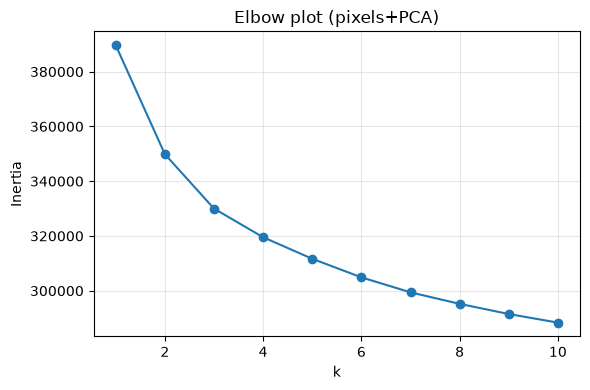

In [5]:
best = comparison.sort_values('ARI (Train)', ascending=False).iloc[0]
best_f, best_k = best['Features'], int(best['k'])
print('Best by ARI:', best_f, 'k =', best_k)
Xtr_best = FEATS[best_f][0]

# Elbow plot for the best feature set
ks = range(1, 11)
inertia = [KMeans(k, n_init=10, random_state=42).fit(Xtr_best).inertia_ for k in ks]
plt.figure(figsize=(6, 4)); plt.plot(list(ks), inertia, marker='o')
plt.xlabel('k'); plt.ylabel('Inertia'); plt.title(f'Elbow plot ({best_f})'); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{RESULTS}/eda_visualizations/kmeans_elbow.png', dpi=200); plt.show()

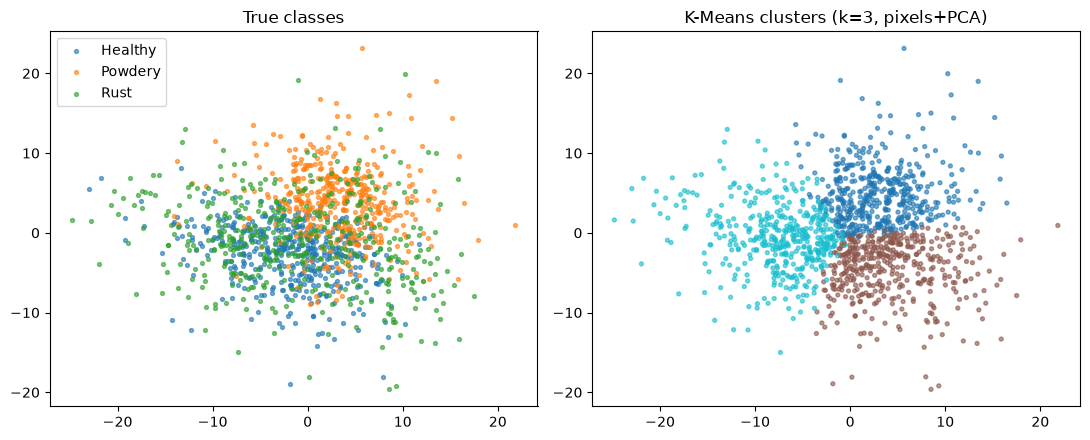

Cluster,0,1,2
True class,,,
Healthy,48,207,203
Powdery,335,77,18
Rust,77,145,212


In [6]:
# True classes vs clusters on a 2D PCA projection of the training pixels
Z = PCA(2, random_state=42).fit_transform(Xtr_best)
labels = models_[(best_f, best_k)].labels_
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for i, c in enumerate(CLASS_NAMES):
    ax[0].scatter(Z[y_tr == i, 0], Z[y_tr == i, 1], s=8, alpha=.6, label=c)
ax[0].set_title('True classes'); ax[0].legend()
ax[1].scatter(Z[:, 0], Z[:, 1], c=labels, cmap='tab10', s=8, alpha=.6)
ax[1].set_title(f'K-Means clusters (k={best_k}, {best_f})')
plt.tight_layout(); plt.savefig(f'{RESULTS}/eda_visualizations/kmeans_vs_true_classes.png', dpi=200); plt.show()

# How the clusters line up with the real classes
pd.crosstab(pd.Series([CLASS_NAMES[i] for i in y_tr], name='True class'), pd.Series(labels, name='Cluster'))

In [7]:
for _, r in comparison.iterrows():
    log_result('K-Means', f"{r['Features']}, k={int(r['k'])}", None, None,
               f"ARI_train={r['ARI (Train)']}, NMI={r['NMI (Train)']}, silhouette={r['Silhouette (Train)']}, ARI_test={r['ARI (Test)']}")

## Conclusion
* K-Means clustering successfully evaluated whether the three true classes (Healthy, Powdery, and Rust) naturally form groups using only raw image features without supervision.
* Based on training ARI, pixel features reduced by PCA with k = 3 gave the highest alignment with the true classes (ARI 0.210, NMI 0.204). However, on the Test set its ARI was only 0.099, while k = 6 reached 0.137 (k = 2 and k = 4 gave 0.124 and 0.125). With only 150 test images these differences are small, so no k is clearly best. All values are low, which shows that raw features do not form clean disease clusters.
* Color histograms performed less effectively for clustering compared to pixel features combined with PCA.
* Overall, while raw features contain some underlying class information, unsupervised clustering alone is insufficient to cleanly and accurately separate complex plant disease categories.

## Limitations
* Low Class Alignment: Because K-Means is completely unsupervised, performance against true class labels remains modest. Test ARIs stay low (0.099 for k=3 with pixels+PCA, and at best 0.137 for k=6), and the k that is best on Train is not the best on Test.
* Weak Internal Cluster Separation: Silhouette scores across feature sets and k values remain relatively low (ranging between 0.048 and 0.154), indicating poor internal cohesion and separation within the clusters.
* Sensitivity to Feature Representation: Clustering quality is heavily constrained by the feature extraction method (pixels with PCA vs. color histograms), requiring careful manual feature engineering.
* Parameter Reliance: The model requires manual comparison of k values and feature sets, and elbow plots show gradual inertia drops rather than sharp optimal cutoffs.